# PHYS 2550 Homework 4, Problem 5: asteroid families

Chengnuo Zhang

Clustering SDSS asteroids in the space of orbital elements (a, e, sin i). The colour index a\* is only used at the end (5.5) as an independent check.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
rng = np.random.default_rng(0)

In [2]:
url = ("https://raw.githubusercontent.com/astroML/"
       "astroML-data/main/datasets/ADR3.dat.gz")
cols = {19: "u", 21: "g", 23: "r", 25: "i", 27: "z", 29: "astar",
        33: "ast_flag", 36: "det_count", 57: "a", 58: "e", 59: "sini"}
raw = pd.read_csv(url, sep=r"\s+", header=None, usecols=list(cols))
raw = raw.rename(columns=cols)
df = raw[(raw.ast_flag == 1) & (raw.det_count == 1)]
df = df[(df.a > 0) & (df.astar > -0.3) & (df.astar < 0.4)
        & (df.i - df.z > -0.8) & (df.i - df.z < 0.6)].reset_index(drop=True)
print(len(df), "asteroids")
df[["a", "e", "sini", "astar"]].describe()

33156 asteroids


,a,e,sini,astar
count,33156.000000,33156.000000,33156.000000,33156.000000
mean,2.645488,0.134283,0.125909,0.051716
std,0.300652,0.057482,0.073030,0.107353
min,2.094620,0.000400,0.000200,-0.290000
25%,2.383678,0.090300,0.065000,-0.040000
50%,2.606440,0.134500,0.111600,0.080000
75%,2.875335,0.172900,0.182100,0.130000
max,3.652860,0.299600,0.300000,0.390000


## 5.1 Look at the data

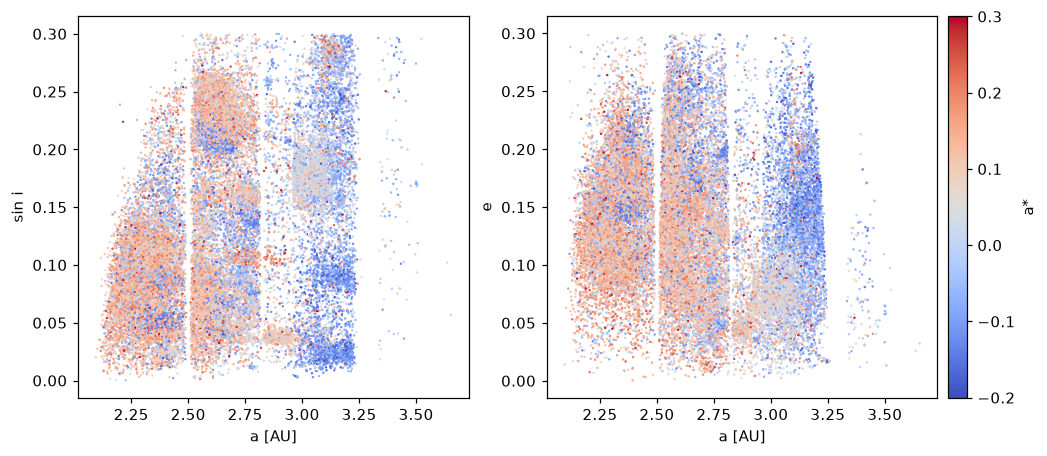

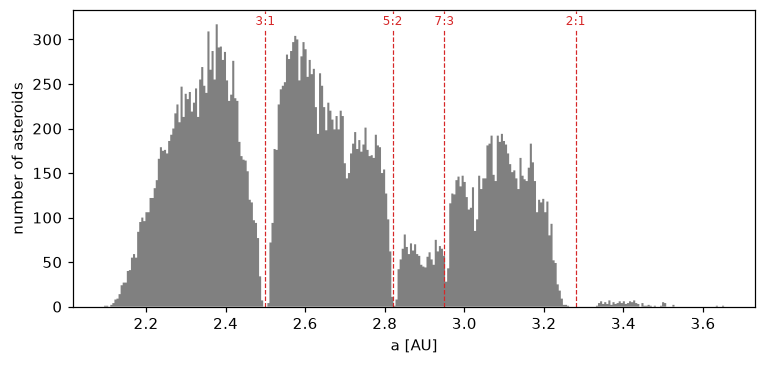

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, y, lab in [(axs[0], "sini", "sin i"), (axs[1], "e", "e")]:
    sc = ax.scatter(df.a, df[y], c=df.astar, s=0.3, cmap="coolwarm", vmin=-0.2, vmax=0.3, rasterized=True)
    ax.set_xlabel("a [AU]"); ax.set_ylabel(lab)
fig.colorbar(sc, ax=axs, label="a*", pad=0.01)
plt.show()

# Kirkwood gaps (mean-motion resonances with Jupiter)
gaps = {"3:1": 2.50, "5:2": 2.82, "7:3": 2.95, "2:1": 3.28}
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df.a, bins=300, histtype="stepfilled", color="0.5")
for name, aj in gaps.items():
    ax.axvline(aj, color="tab:red", ls="--", lw=0.8)
    ax.text(aj, ax.get_ylim()[1] * 0.95, name, color="tab:red", ha="center", fontsize=8,
            bbox=dict(fc="white", ec="none", pad=1))
ax.set_xlabel("a [AU]"); ax.set_ylabel("number of asteroids")
plt.show()

**What I see.** The (a, sin i) plane is far from uniform. There are empty vertical strips at a ≈ 2.50, 2.82, 2.95 and 3.28 AU, which also show up as deep minima in the histogram of a. These are the Kirkwood gaps: at these distances the orbital period is a simple fraction of Jupiter's (3:1, 5:2, 7:3, 2:1) and the resonance has cleared the asteroids out. The gaps split the belt into an inner part (2.1–2.5 AU), a middle part (2.5–2.82 AU), a thin zone between 2.82 and 2.95 AU and an outer part (2.95–3.3 AU), plus a few objects beyond 3.3 AU.

On top of this smooth background there are small, dense clumps, for example around (a, sin i) ≈ (2.36, 0.11), (2.39, 0.04), (2.62, 0.23), (2.89, 0.04), (3.01, 0.17) and (3.15, 0.02). They are much tighter than the background, so these should be the collisional families.

The colour also changes in a systematic way. The inner belt is mostly red (a* > 0, rocky; mean a* ≈ 0.08 inside 2.5 AU), while the outer belt is clearly bluer (mean a* ≈ −0.02 beyond 2.95 AU) and contains many of the carbon-rich asteroids with a* < 0. Inside one clump the colour looks fairly uniform: the clump at (3.15, 0.02) is clearly blue, while the one at (2.62, 0.23) is red. In the (a, e) plane the clumps are harder to see because e is more spread out within a family.

## 5.2 Preprocessing

In [4]:
feat = ["a", "e", "sini"]
X_raw = df[feat].to_numpy()
print("standard deviations:")
print(df[feat].std().round(4).to_string())
X = StandardScaler().fit_transform(X_raw)
print("\nafter StandardScaler:", X.std(axis=0).round(3))

standard deviations:
a       0.3007
e       0.0575
sini    0.0730

after StandardScaler: [1. 1. 1.]


The raw standard deviations are 0.30 AU for a, 0.057 for e and 0.073 for sin i, so in absolute numbers a varies 4–5 times more than the other two. Without scaling, the Euclidean distance would be dominated by a: both k-means and DBSCAN would basically slice the belt along a and almost ignore e and sin i, even though the families are just as compact in those directions. The features also have different units (AU vs. dimensionless), so comparing their raw sizes doesn't really mean anything.

After StandardScaler every feature has mean 0 and standard deviation 1, so one standard deviation counts the same in each direction. It also means the DBSCAN radius is measured in standard deviations: R = 0.1 corresponds to about 0.030 AU in a, 0.006 in e and 0.007 in sin i.

## 5.3 k-means

k =  2   inertia =   66225.6   silhouette = 0.328
k =  3   inertia =   48725.5   silhouette = 0.350


k =  4   inertia =   39909.9   silhouette = 0.342
k =  5   inertia =   32713.6   silhouette = 0.314


k =  6   inertia =   28180.7   silhouette = 0.329
k =  7   inertia =   24259.7   silhouette = 0.344


k =  8   inertia =   21732.9   silhouette = 0.351
k =  9   inertia =   20071.3   silhouette = 0.347


k = 10   inertia =   18579.8   silhouette = 0.334


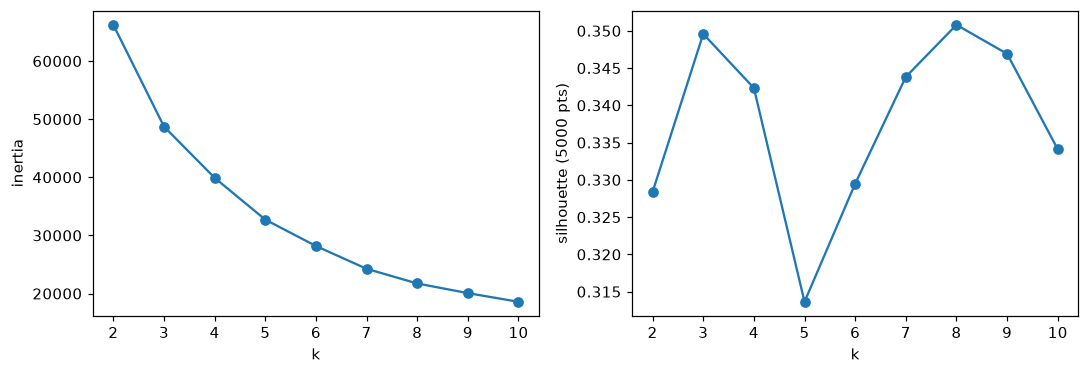

In [5]:
ks = range(2, 11)
sub = rng.choice(len(X), 5000, replace=False)   # same subsample for every k
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X[sub], km.labels_[sub]))
    print(f"k = {k:2d}   inertia = {km.inertia_:9.1f}   silhouette = {sil[-1]:.3f}")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(list(ks), inertia, "o-"); axs[0].set_xlabel("k"); axs[0].set_ylabel("inertia")
axs[1].plot(list(ks), sil, "o-"); axs[1].set_xlabel("k"); axs[1].set_ylabel("silhouette (5000 pts)")
plt.tight_layout(); plt.show()

**Choosing k.** The inertia goes down smoothly (66.2k, 48.7k, 39.9k, 32.7k, …, 18.6k for k = 2…10) and there is no sharp elbow: it drops by 26% from k = 2 to 3, by 18% from 3 to 4 and again by 18% from 4 to 5, and by 14% or less after that, so at most there is a weak bend around k = 4–5. The silhouette is flat, between 0.31 and 0.35 for all k. The highest values are at k = 3 (0.350) and k = 8 (0.351), and k = 4 is almost the same (0.342). None of these is a convincing best k, which tells me that the data is not made of a few round, well-separated blobs, which is what k-means assumes.

I chose **k = 4**: it sits at that weak bend, its silhouette is basically as good as the maximum while k = 5 has the lowest silhouette of all (0.314), and it is still small enough to interpret.

The cluster plot shows what k-means actually does. It cuts the belt into a few big regions: the inner belt (cluster 0, reaching a little past the 3:1 gap), the low-inclination part of the middle and outer belt (cluster 1), and two high-inclination groups that are split by eccentricity (cluster 2 with high e, cluster 3 with low e). The boundaries ignore both the Kirkwood gaps and the dense clumps. For example cluster 1 runs straight across the gaps at 2.82 and 2.95 AU, and the clump at (2.62, 0.23) is shared between clusters 2 and 3. So these are large chunks of orbital space, not families.

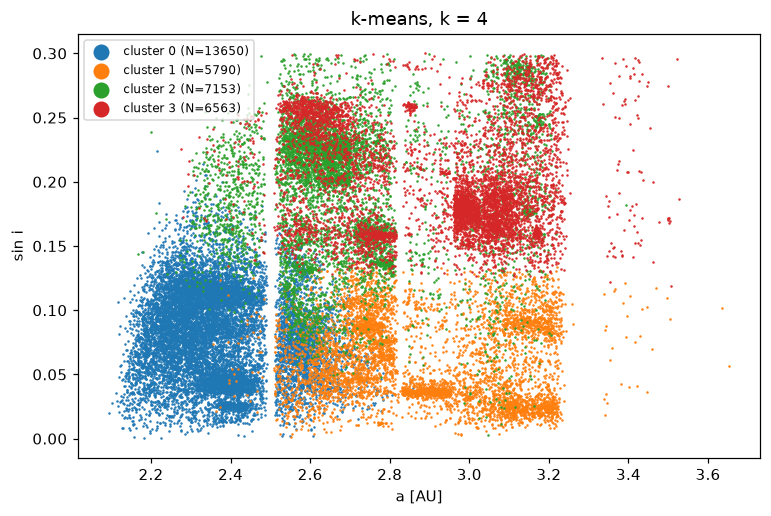

In [6]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X)
df["km"] = km.labels_

fig, ax = plt.subplots(figsize=(8, 5))
for c in range(K):
    m = df.km == c
    ax.scatter(df.a[m], df.sini[m], s=0.4, label=f"cluster {c} (N={m.sum()})", rasterized=True)
ax.set_xlabel("a [AU]"); ax.set_ylabel("sin i"); ax.set_title(f"k-means, k = {K}")
ax.legend(markerscale=15, fontsize=8, loc="upper left")
plt.show()

In [7]:
rows = []
for init in ["random", "k-means++"]:
    for seed in range(10):
        m = KMeans(n_clusters=K, init=init, n_init=1, random_state=seed).fit(X)
        rows.append(dict(init=init, seed=seed, inertia=m.inertia_, n_iter=m.n_iter_))
runs = pd.DataFrame(rows)
print(runs.pivot(index="seed", columns="init", values=["inertia", "n_iter"]).round(1).to_string())
print()
print(runs.groupby("init")[["inertia", "n_iter"]].agg(["mean", "std", "min", "max"]).round(2).to_string())

       inertia             n_iter       
init k-means++   random k-means++ random
seed                                    
0      40333.6  40334.6      38.0   16.0
1      39909.9  40333.1      16.0   14.0
2      39909.7  39909.9      18.0   14.0
3      39910.1  40684.8       9.0   10.0
4      40685.2  39910.1      38.0   14.0
5      40798.6  40685.4      20.0   28.0
6      40801.1  40685.8      14.0   25.0
7      40333.4  39910.0      14.0   17.0
8      42406.5  39909.9      13.0   15.0
9      40332.4  42406.5      48.0   17.0

            inertia                             n_iter               
               mean     std       min       max   mean    std min max
init                                                                 
k-means++  40542.06  742.33  39909.74  42406.55   22.8  13.40   9  48
random     40477.01  758.68  39909.94  42406.55   17.0   5.44  10  28


**Random vs. k-means++ (k = 4, 10 runs each with n_init = 1).** Both methods end up in the same handful of local minima, with final inertia of about 39910, 40333, 40685, 40800 or 42407. k-means++ reached the lowest value (≈ 39910) in 3 of 10 runs and random initialisation in 4 of 10. The mean final inertia is about the same (40542 ± 742 for k-means++, 40477 ± 759 for random) and the worst run is identical (42407). k-means++ actually needed more iterations on average (22.8, range 9–48) than random (17.0, range 10–28).

So on this data set k-means++ gives no clear advantage. My guess is that this happens because for k = 4 there are no well-separated groups to find. J has several minima of similar depth, and with 33k points four randomly chosen asteroids are already spread over the belt anyway. The more important point is the spread between runs: one run can end up about 6% worse than another, so in practice you should use several initialisations (n_init > 1) and keep the best one, as I did above.

## 5.4 DBSCAN

In [8]:
summary = []
db_labels = {}
for eps in [0.05, 0.08, 0.10, 0.15]:
    lab = DBSCAN(eps=eps, min_samples=20).fit_predict(X)
    db_labels[eps] = lab
    n_cl = lab.max() + 1
    sizes = np.bincount(lab[lab >= 0]) if n_cl > 0 else np.array([0])
    summary.append(dict(R=eps, n_clusters=n_cl, noise_frac=np.mean(lab == -1),
                        largest_cluster_frac=sizes.max() / len(lab)))
print(pd.DataFrame(summary).round(3).to_string(index=False))

   R  n_clusters  noise_frac  largest_cluster_frac
0.05          21       0.937                 0.010
0.08          39       0.761                 0.048
0.10          42       0.614                 0.183
0.15          28       0.313                 0.287


With MinPts = 20 the result depends a lot on R:

| R | clusters | noise | largest cluster |
|---|---|---|---|
| 0.05 | 21 | 94% | 1% |
| 0.08 | 39 | 76% | 5% |
| 0.10 | 42 | 61% | 18% |
| 0.15 | 28 | 31% | 29% |

A small R keeps only the very densest cores and labels almost everything as noise. As R grows, the clusters spread into the background until neighbouring families and the background between them merge. That is why the number of clusters goes down again at R = 0.15, while a single cluster takes up almost a third of the sample.

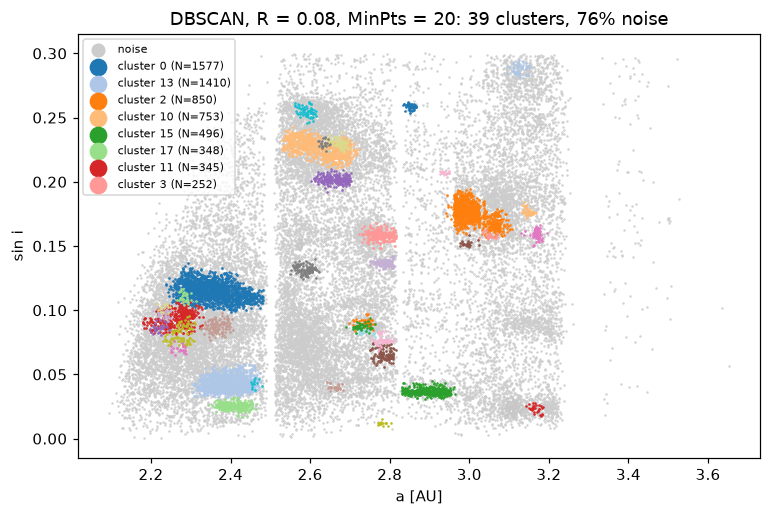

In [9]:
EPS = 0.08
df["db"] = db_labels[EPS]
fig, ax = plt.subplots(figsize=(8, 5))
noise = df.db == -1
ax.scatter(df.a[noise], df.sini[noise], s=0.3, color="0.8", label="noise", rasterized=True)
cmap = plt.get_cmap("tab20")
order = df.db[~noise].value_counts().index        # biggest clusters first
for n, c in enumerate(order):
    m = df.db == c
    ax.scatter(df.a[m], df.sini[m], s=0.5, color=cmap(n % 20), rasterized=True,
               label=f"cluster {c} (N={m.sum()})" if n < 8 else None)
ax.set_xlabel("a [AU]"); ax.set_ylabel("sin i")
ax.set_title(f"DBSCAN, R = {EPS}, MinPts = 20: {len(order)} clusters, {noise.mean():.0%} noise")
ax.legend(markerscale=15, fontsize=7, loc="upper left")
plt.show()

**Choosing R.** I chose **R = 0.08**. At R = 0.05 almost everything is noise and only the centres of the families survive. At R = 0.10 the separate clumps in the inner belt (a ≈ 2.2–2.45 AU) have already merged into one cluster of about 6000 asteroids, so we start losing the families we are looking for. At R = 0.08 the clusters are compact clumps that match the dense spots I saw by eye in 5.1, e.g. at (2.36, 0.11), (2.39, 0.04), (2.62, 0.23), (2.89, 0.04) and (3.01, 0.17). The cost is that 76% of the asteroids are labelled noise. I think that's acceptable here, because most asteroids are not members of a family. The choice is not perfect: the blue clump at (3.15, 0.02) is only a small cluster (< 300 members) at R = 0.08 and becomes a proper cluster only at R = 0.10, because it is more spread out in e than the others.

## 5.5 A physical check

In [10]:
sigma_all = df.astar.std()
print(f"std of a* over the whole sample: {sigma_all:.4f}\n")

def colour_stats(col, name):
    big = df[df[col] >= 0].groupby(col).astar.agg(["size", "mean", "std"])
    big = big[big["size"] >= 300].sort_values("size", ascending=False)
    w_avg = np.average(big["std"], weights=big["size"])
    print(f"{name}: {len(big)} clusters with >= 300 members "
          f"({big['size'].sum()} asteroids = {big['size'].sum()/len(df):.0%} of the sample)")
    print(big.round(3).to_string())
    print(f"size-weighted mean of per-cluster std(a*) = {w_avg:.4f}"
          f"   (ratio to whole sample: {w_avg/sigma_all:.2f})\n")
    return big, w_avg

big_km, w_km = colour_stats("km", f"k-means (k={K})")
big_db, w_db = colour_stats("db", f"DBSCAN (R={EPS})")

std of a* over the whole sample: 0.1074

k-means (k=4): 4 clusters with >= 300 members (33156 asteroids = 100% of the sample)
     size   mean    std
km                     
0   13650  0.082  0.099
2    7153  0.038  0.113
3    6563  0.037  0.091
1    5790  0.013  0.115
size-weighted mean of per-cluster std(a*) = 0.1035   (ratio to whole sample: 0.96)

DBSCAN (R=0.08): 7 clusters with >= 300 members (5779 asteroids = 17% of the sample)
    size   mean    std
db                    
0   1577  0.114  0.062
13  1410  0.078  0.113
2    850  0.047  0.047
10   753  0.124  0.057
15   496  0.084  0.052
17   348  0.071  0.060
11   345  0.052  0.099
size-weighted mean of per-cluster std(a*) = 0.0727   (ratio to whole sample: 0.68)



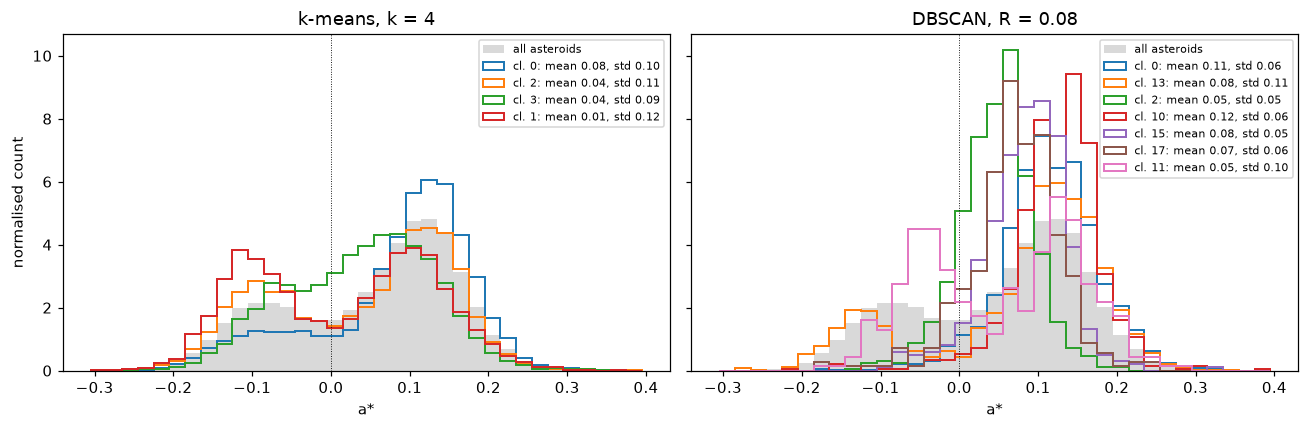

In [11]:
bins = np.arange(-0.305, 0.41, 0.02)   # a* is given in steps of 0.01, so put the bin edges between values
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, big, col, title in [(axs[0], big_km, "km", f"k-means, k = {K}"),
                            (axs[1], big_db, "db", f"DBSCAN, R = {EPS}")]:
    ax.hist(df.astar, bins=bins, density=True, histtype="stepfilled", color="0.85", label="all asteroids")
    for c in big.index:
        ax.hist(df.astar[df[col] == c], bins=bins, density=True, histtype="step", lw=1.3,
                label=f"cl. {c}: mean {big.loc[c, 'mean']:.2f}, std {big.loc[c, 'std']:.2f}")
    ax.axvline(0, color="k", lw=0.6, ls=":")
    ax.set_xlabel("a*"); ax.set_title(title); ax.legend(fontsize=7)
axs[0].set_ylabel("normalised count")
plt.tight_layout(); plt.show()

In [12]:
# Fairness check: put the same asteroids through both algorithms.
# Restrict k-means to the points DBSCAN kept in big clusters and recompute its weighted std there.
keep = df.db.isin(big_db.index)
sub_km = df[keep].groupby("km").astar.agg(["size", "std"])
sub_km = sub_km[sub_km["size"] >= 300]
print(f"k-means on the same {keep.sum()} asteroids DBSCAN kept: "
      f"weighted std = {np.average(sub_km['std'], weights=sub_km['size']):.4f}")

# And a k-means with as many clusters as DBSCAN found, on all points
km_many = KMeans(n_clusters=len(big_db), n_init=10, random_state=0).fit(X)
s = df.assign(kk=km_many.labels_).groupby("kk").astar.agg(["size", "std"])
s = s[s["size"] >= 300]
print(f"k-means with k = {len(big_db)}: weighted std = {np.average(s['std'], weights=s['size']):.4f}")

k-means on the same 5779 asteroids DBSCAN kept: weighted std = 0.0767
k-means with k = 7: weighted std = 0.0966


**Results.** The standard deviation of a* over the whole sample is 0.107.

- **k-means (k = 4):** all four clusters have more than 300 members and together contain every asteroid. Their means are between 0.01 and 0.08 and their standard deviations between 0.09 and 0.12. The size-weighted average is **0.104**, i.e. 96% of the full-sample value. The histograms look almost like the histogram of the whole sample.
- **DBSCAN (R = 0.08):** 7 clusters have at least 300 members, 5779 asteroids or 17% of the sample. Their standard deviations range from 0.047 to 0.113, and the size-weighted average is **0.073**, 68% of the full-sample value. Most histograms are narrow peaks at different positions. Cluster 2 at (3.01, 0.18) peaks around a* ≈ 0.05, while clusters 0 and 10 sit at about 0.11–0.12. Two clusters are wider (13 and 11, std ≈ 0.10–0.11). Cluster 13 has two bumps, one below zero and one around 0.1, so it looks like two groups of different composition that overlap in (a, e, sin i). These are probably two families that the orbits alone can't separate.

**Interpretation.** DBSCAN gives groups that are clearly more homogeneous in colour. Colour was not used for the clustering at all, and fragments of the same parent body are made of the same material. So this is good evidence that the DBSCAN clusters are real collisional families. The k-means clusters are just large regions of the belt that mix many families with background asteroids, and their colour spread is almost as large as that of the whole belt.

**Is the comparison fair?** Not completely:
1. DBSCAN only keeps 17% of the asteroids (the densest cores) and throws the rest into noise, so the background and the outskirts of the families, which would add colour spread, are simply not counted. k-means has to place every asteroid somewhere.
2. DBSCAN has 7 large clusters and k-means only 4, and smaller groups are more homogeneous anyway.

I checked both effects (last cell). If I take the k-means labels of only the 5779 asteroids that DBSCAN put in large clusters, the weighted std is already 0.077, close to DBSCAN's 0.073. Running k-means with k = 7 on the full sample only brings it down to 0.097. So most of the difference comes from DBSCAN being allowed to say "this asteroid does not belong to any family", not from better cluster boundaries. For this physics question that is actually what we want, but a fully fair comparison would need the same number of clusters and the same set of asteroids.